# EV Charging Demand — Exploratory Data Analysis (EDA)

# Step 1 — Load Cleaned Dataset

In [2]:
import pandas as pd

df = pd.read_csv("Data_row/cleaned data/ChargingRecords_Cleaned.csv")

df.head()

,UserID,ChargerID,ChargerCompany,Location,ChargerType,StartDay,StartTime,EndDay,EndTime,StartDatetime,EndDatetime,Duration,Demand,CalculateDuration,PreciseDuration,InvalidNegativeDuration,ZeroDurationRecoverable,ZeroDurationUnresolved,CleanedDuration
0,0,1,1,hotel,0,2022-09-15,20:54:02,2022-09-15,23:59:13,2022-09-15 20:54:00,2022-09-15 23:59:00,185,20.36,185.0,185.183333,False,False,False,185.0
1,0,1,1,hotel,0,2022-09-14,20:01:05,2022-09-14,21:31:04,2022-09-14 20:01:00,2022-09-14 21:31:00,90,10.19,90.0,89.983333,False,False,False,90.0
2,0,1,1,hotel,0,2022-09-14,18:54:30,2022-09-14,19:54:29,2022-09-14 18:54:00,2022-09-14 19:54:00,60,6.78,60.0,59.983333,False,False,False,60.0
3,0,1,1,hotel,0,2022-09-29,18:32:51,2022-09-30,0:16:42,2022-09-29 18:32:00,2022-09-30 00:16:00,344,37.65,344.0,343.850000,False,False,False,344.0
4,0,1,1,hotel,0,2022-09-25,19:30:15,2022-09-26,0:30:14,2022-09-25 19:30:00,2022-09-26 00:30:00,300,33.81,300.0,299.983333,False,False,False,300.0


# Step 2: Check Dataset Shape

In [3]:
df.shape

(72843, 19)

# Step 3 — Check Column Names

In [4]:
df.columns

Index(['UserID', 'ChargerID', 'ChargerCompany', 'Location', 'ChargerType',
       'StartDay', 'StartTime', 'EndDay', 'EndTime', 'StartDatetime',
       'EndDatetime', 'Duration', 'Demand', 'CalculateDuration',
       'PreciseDuration', 'InvalidNegativeDuration', 'ZeroDurationRecoverable',
       'ZeroDurationUnresolved', 'CleanedDuration'],
      dtype='str')

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 72843 entries, 0 to 72842
Data columns (total 19 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UserID                   72843 non-null  int64  
 1   ChargerID                72843 non-null  int64  
 2   ChargerCompany           72843 non-null  int64  
 3   Location                 72843 non-null  str    
 4   ChargerType              72843 non-null  int64  
 5   StartDay                 72843 non-null  str    
 6   StartTime                72843 non-null  str    
 7   EndDay                   72843 non-null  str    
 8   EndTime                  72843 non-null  str    
 9   StartDatetime            72843 non-null  str    
 10  EndDatetime              72843 non-null  str    
 11  Duration                 72843 non-null  int64  
 12  Demand                   72843 non-null  float64
 13  CalculateDuration        72843 non-null  float64
 14  PreciseDuration          72843 no

In [6]:
df["StartDatetime"] = pd.to_datetime(df["StartDatetime"])
df["EndDatetime"] = pd.to_datetime(df["EndDatetime"])

In [7]:
df[["StartDatetime", "EndDatetime"]].dtypes

StartDatetime    datetime64[us]
EndDatetime      datetime64[us]
dtype: object

In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 72843 entries, 0 to 72842
Data columns (total 19 columns):
 #   Column                   Non-Null Count  Dtype         
---  ------                   --------------  -----         
 0   UserID                   72843 non-null  int64         
 1   ChargerID                72843 non-null  int64         
 2   ChargerCompany           72843 non-null  int64         
 3   Location                 72843 non-null  str           
 4   ChargerType              72843 non-null  int64         
 5   StartDay                 72843 non-null  str           
 6   StartTime                72843 non-null  str           
 7   EndDay                   72843 non-null  str           
 8   EndTime                  72843 non-null  str           
 9   StartDatetime            72843 non-null  datetime64[us]
 10  EndDatetime              72843 non-null  datetime64[us]
 11  Duration                 72843 non-null  int64         
 12  Demand                   72843 non-null  fl

# Step 5 — Find Charging Sessions by Hour
We want to know at what time people start charging their EVs.

In [9]:
df["StartHour"] = df["StartDatetime"].dt.hour

df[["StartDatetime", "StartHour"]].head()

,StartDatetime,StartHour
0,2022-09-15 20:54:00,20
1,2022-09-14 20:01:00,20
2,2022-09-14 18:54:00,18
3,2022-09-29 18:32:00,18
4,2022-09-25 19:30:00,19


# Step 6 — Count Charging Sessions by Hour
 Find out which hour has the most EV charging sessions

In [10]:
df["StartHour"].value_counts().sort_index()

StartHour
0      919
1      449
2      200
3      134
4      190
5      549
6     1214
7     2291
8     4143
9     4056
10    3307
11    3177
12    3858
13    3776
14    3895
15    4215
16    5144
17    6357
18    6509
19    5504
20    4760
21    3979
22    2433
23    1784
Name: count, dtype: int64

# Step 7 — Visualize Charging Sessions by Hour

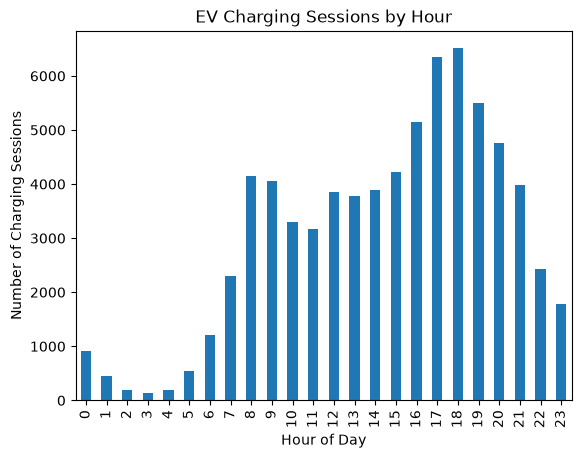

In [11]:
import matplotlib.pyplot as plt

df["StartHour"].value_counts().sort_index().plot(kind="bar")

plt.xlabel("Hour of Day")
plt.ylabel("Number of Charging Sessions")
plt.title("EV Charging Sessions by Hour")
plt.show()

# Step 8 — Total Charging Demand by Start Hour

In [ ]:
df.groupby("StartHour")["Demand"].sum() #groupby("StartHour") → Groups charging sessions by their starting hour.

StartHour
0      24396.87
1      11368.29
2       5007.37
3       2713.46
4       3469.31
5       9467.91
6      20619.98
7      38513.69
8      72574.42
9      58440.79
10     44382.51
11     43584.70
12     51763.63
13     51753.83
14     54907.64
15     59269.10
16     80009.65
17    108031.62
18    119394.82
19    110087.22
20    102569.92
21     90909.38
22     57898.62
23     49441.48
Name: Demand, dtype: float64

# Step 9 — Total Charging Demand by Hour (Chart)

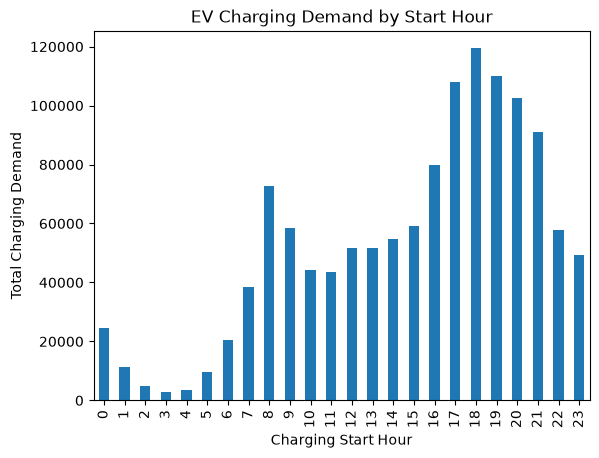

In [12]:
df.groupby("StartHour")["Demand"].sum().plot(kind="bar")

plt.xlabel("Charging Start Hour")
plt.ylabel("Total Charging Demand")
plt.title("EV Charging Demand by Start Hour")
plt.show()

# Step 10 — Total Charging Demand by Location

In [15]:
df.groupby("Location")["Demand"].sum()

Location
accommodation           5433.44
apartment             263103.12
bus garage               829.04
camping                41606.22
company               122786.43
golf                   17203.13
hotel                 126416.10
market                 49784.85
public area           251958.87
public institution    122195.41
public parking lot     58334.41
resort                153004.54
restaurant             39580.76
sightseeing            18339.89
Name: Demand, dtype: float64

# Step 11 — Charging Demand by Location (Chart)

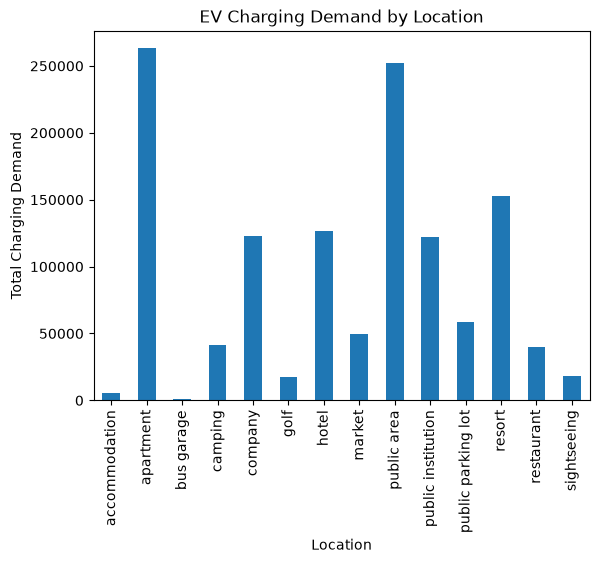

In [16]:
df.groupby("Location")["Demand"].sum().plot(kind="bar")

plt.xlabel("Location")
plt.ylabel("Total Charging Demand")
plt.title("EV Charging Demand by Location")
plt.show()

In [17]:
df["Location"].unique()

<ArrowStringArray>
[             'hotel',            'company',          'apartment',
             'resort',        'public area', 'public institution',
         'restaurant',      'accommodation',               'golf',
        'sightseeing',             'market',            'camping',
 'public parking lot',         'bus garage']
Length: 14, dtype: str

# Step 11: Location Demand Chart

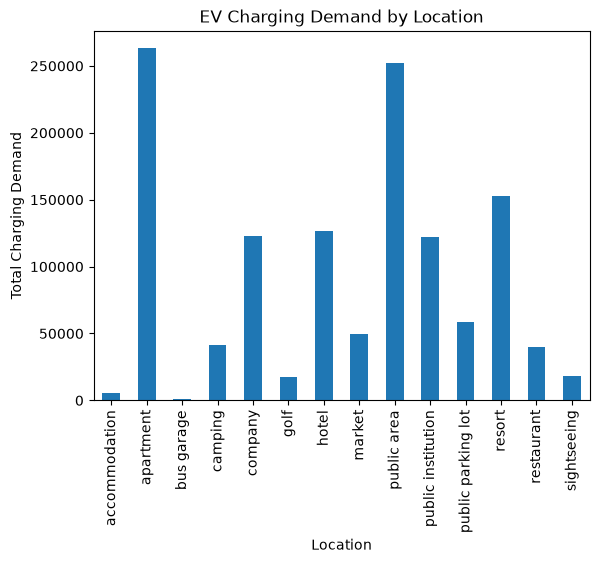

In [18]:
df.groupby("Location")["Demand"].sum().plot(kind="bar")

plt.xlabel("Location")
plt.ylabel("Total Charging Demand")
plt.title("EV Charging Demand by Location")
plt.show()

# Step 12 — Charging Sessions by Location

In [19]:
df["Location"].value_counts()

Location
public area           14076
apartment             14036
resort                 8854
hotel                  8598
company                7557
public institution     7023
public parking lot     3394
market                 3005
restaurant             2222
camping                1630
sightseeing            1203
golf                   1029
accommodation           187
bus garage               29
Name: count, dtype: int64

# Step 13 — Charging Sessions by Location (Chart)

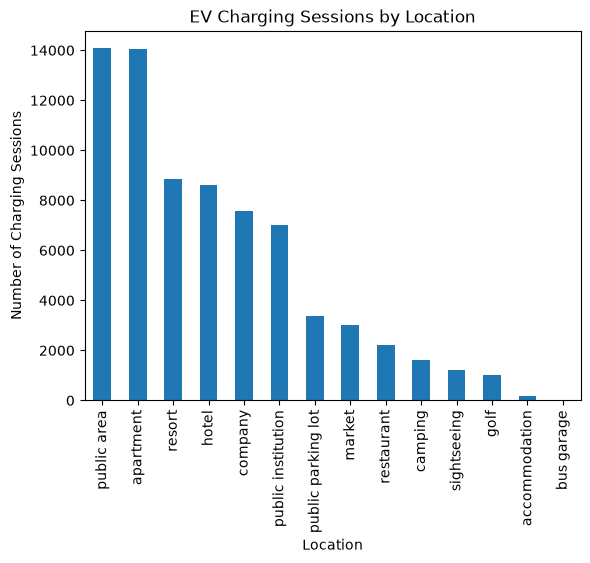

In [20]:
df["Location"].value_counts().plot(kind="bar")

plt.xlabel("Location")
plt.ylabel("Number of Charging Sessions")
plt.title("EV Charging Sessions by Location")
plt.show()

# Step 14 — Charging Sessions by Charger Type

In [21]:
df["ChargerType"].value_counts().sort_index()

ChargerType
0    57896
1    14947
Name: count, dtype: int64

# Step 15 — Charging Sessions by Charger Type (Chart)

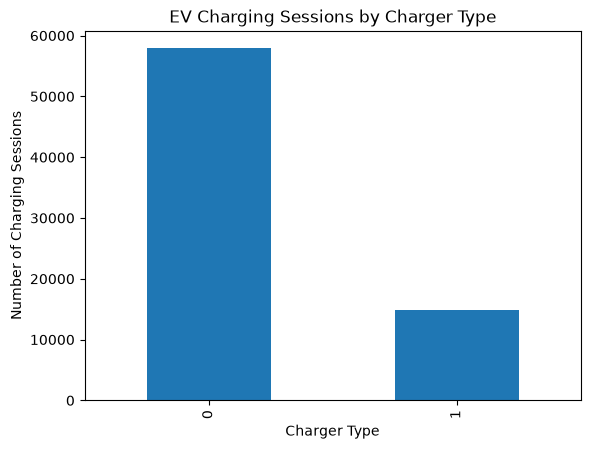

In [22]:
df["ChargerType"].value_counts().sort_index().plot(kind="bar")

plt.xlabel("Charger Type")
plt.ylabel("Number of Charging Sessions")
plt.title("EV Charging Sessions by Charger Type")
plt.show()

# Step 16 — Total Charging Demand by Charger Type

In [23]:
df.groupby("ChargerType")["Demand"].sum()

ChargerType
0    987242.32
1    283333.89
Name: Demand, dtype: float64

# Step 17 — Total Charging Demand by Charger Type (Chart)

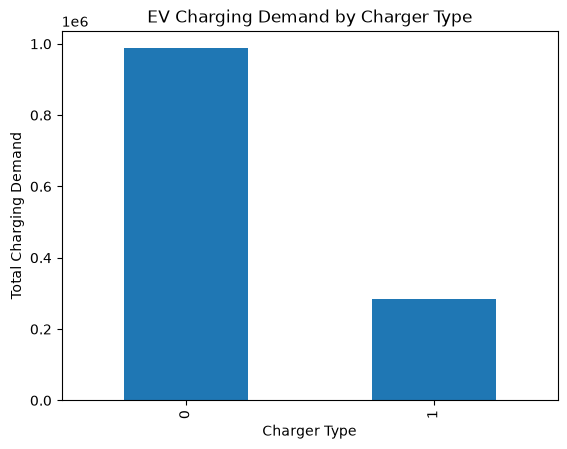

In [24]:
df.groupby("ChargerType")["Demand"].sum().plot(kind="bar")

plt.xlabel("Charger Type")
plt.ylabel("Total Charging Demand")
plt.title("EV Charging Demand by Charger Type")
plt.show()

# Step 18 — Average Charging Demand by Charger Type

In [25]:
df.groupby("ChargerType")["Demand"].mean().round(2)

ChargerType
0    17.05
1    18.96
Name: Demand, dtype: float64

# Step 19 — Average Demand by Charger Type (Chart)

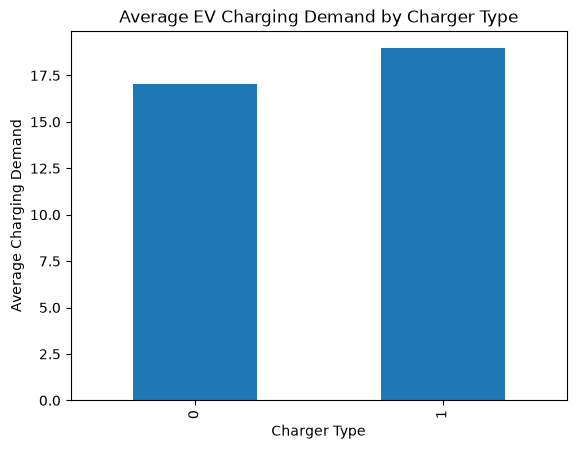

In [26]:
df.groupby("ChargerType")["Demand"].mean().plot(kind="bar")

plt.xlabel("Charger Type")
plt.ylabel("Average Charging Demand")
plt.title("Average EV Charging Demand by Charger Type")
plt.show()

# Step 20 — Average Charging Duration by Charger Type

In [27]:
df.groupby("ChargerType")["CleanedDuration"].mean().round(2)

ChargerType
0    181.42
1     36.05
Name: CleanedDuration, dtype: float64

# Step 21 — Average Charging Duration by Charger Type (Chart)

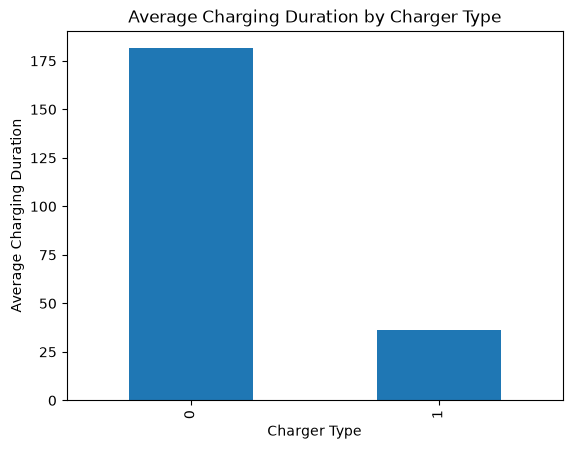

In [29]:
df.groupby("ChargerType")["CleanedDuration"].mean().plot(kind="bar")

plt.xlabel("Charger Type")
plt.ylabel("Average Charging Duration")
plt.title("Average Charging Duration by Charger Type")
plt.show()

# Step 22 — Relationship Between Charging Duration and Demand
 Check whether longer charging sessions generally have higher demand.

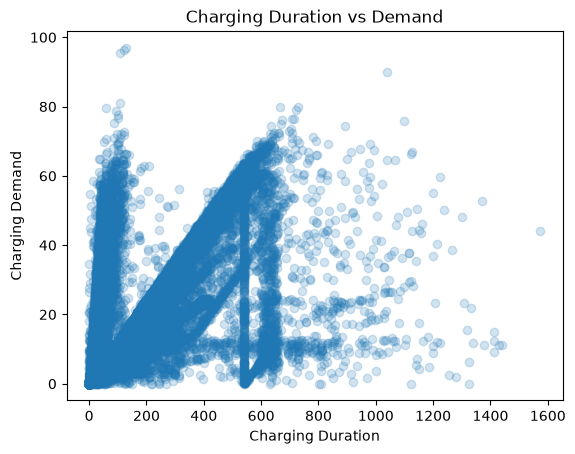

In [30]:
plt.scatter(df["CleanedDuration"], df["Demand"], alpha=0.2)

plt.xlabel("Charging Duration")
plt.ylabel("Charging Demand")
plt.title("Charging Duration vs Demand")
plt.show()

# Step 23 — Correlation Between Duration and Demand

In [31]:
df["CleanedDuration"].corr(df["Demand"])

np.float64(0.6584832430804557)

# Step 24 — Average Charging Demand by Location

In [32]:
df.groupby("Location")["Demand"].mean().round(2).sort_values(ascending=False)

Location
accommodation         29.06
bus garage            28.59
camping               25.53
apartment             18.74
public area           17.90
restaurant            17.81
public institution    17.40
resort                17.28
public parking lot    17.19
golf                  16.72
market                16.57
company               16.25
sightseeing           15.25
hotel                 14.70
Name: Demand, dtype: float64

# Step 25 — Average Charging Demand by Location (Chart)

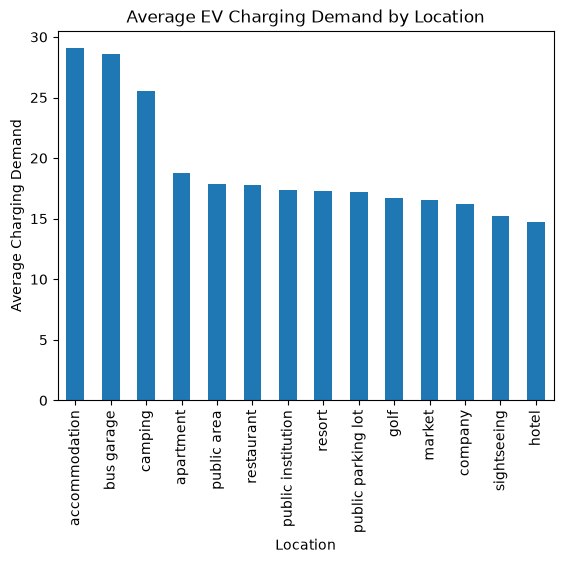

In [33]:
df.groupby("Location")["Demand"].mean().sort_values(ascending=False).plot(kind="bar")

plt.xlabel("Location")
plt.ylabel("Average Charging Demand")
plt.title("Average EV Charging Demand by Location")
plt.show()

# Step 26 — Charging Sessions by Day of the Week

In [34]:
df["DayOfWeek"] = df["StartDatetime"].dt.day_name()

df["DayOfWeek"].value_counts()

DayOfWeek
Thursday     11053
Friday       11010
Wednesday    10879
Tuesday      10646
Monday       10322
Saturday      9943
Sunday        8990
Name: count, dtype: int64

# Step 27 — Charging Sessions by Day (Chart)

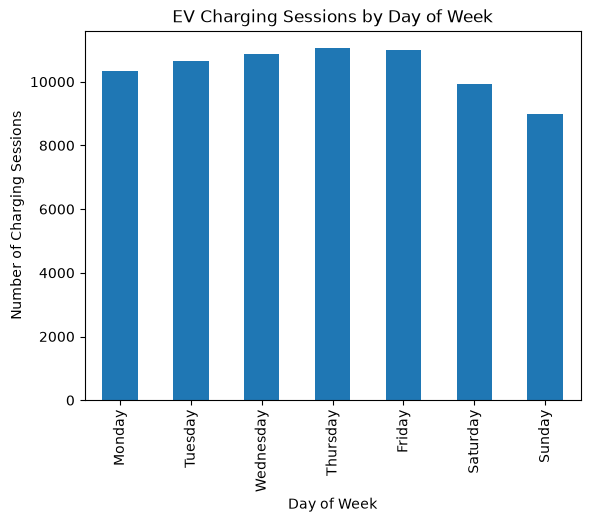

In [35]:
day_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]

df["DayOfWeek"].value_counts().reindex(day_order).plot(kind="bar")

plt.xlabel("Day of Week")
plt.ylabel("Number of Charging Sessions")
plt.title("EV Charging Sessions by Day of Week")
plt.show()

# Step 28 — Total Charging Demand by Day of Week

In [36]:
df.groupby("DayOfWeek")["Demand"].sum().reindex(day_order).round(2)

DayOfWeek
Monday       179117.20
Tuesday      182065.69
Wednesday    190690.88
Thursday     194873.22
Friday       190548.37
Saturday     173208.88
Sunday       160071.97
Name: Demand, dtype: float64

# Step 29 — Total Charging Demand by Day (Chart)

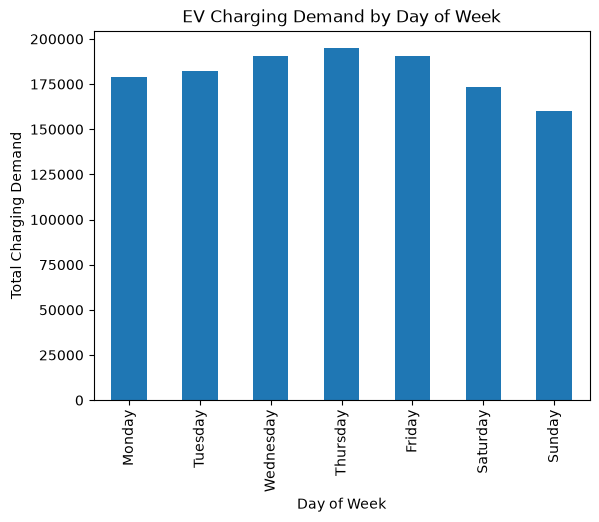

In [37]:
df.groupby("DayOfWeek")["Demand"].sum().reindex(day_order).plot(kind="bar")

plt.xlabel("Day of Week")
plt.ylabel("Total Charging Demand")
plt.title("EV Charging Demand by Day of Week")
plt.show()

# Step 30 — Average Charging Demand by Day of Week

In [38]:
df.groupby("DayOfWeek")["Demand"].mean().reindex(day_order).round(2)

DayOfWeek
Monday       17.35
Tuesday      17.10
Wednesday    17.53
Thursday     17.63
Friday       17.31
Saturday     17.42
Sunday       17.81
Name: Demand, dtype: float64

# Step 31 — Average Charging Demand by Day (Chart)

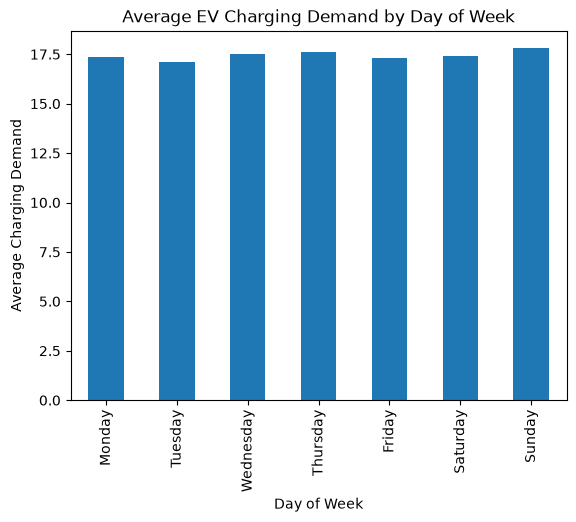

In [39]:
df.groupby("DayOfWeek")["Demand"].mean().reindex(day_order).plot(kind="bar")

plt.xlabel("Day of Week")
plt.ylabel("Average Charging Demand")
plt.title("Average EV Charging Demand by Day of Week")
plt.show()

# Step 32 — Charging Sessions by Month

In [13]:
df["Month"] = df["StartDatetime"].dt.month

df["Month"].value_counts().sort_index()

Month
1     6307
2     5840
3     5948
4     6006
5     6691
6     6729
7     7888
8     8083
9     6282
10    3930
11    4281
12    4858
Name: count, dtype: int64

# Step 33 — Check Years in the Dataset

In [14]:
df["StartDatetime"].dt.year.value_counts().sort_index()

StartDatetime
2021    13088
2022    59755
Name: count, dtype: int64

# Step 34 — Charging Sessions by Year and Month

In [15]:
df["YearMonth"] = df["StartDatetime"].dt.to_period("M")

df["YearMonth"].value_counts().sort_index()

YearMonth
2021-09      19
2021-10    3930
2021-11    4281
2021-12    4858
2022-01    6307
2022-02    5840
2022-03    5948
2022-04    6006
2022-05    6691
2022-06    6729
2022-07    7888
2022-08    8083
2022-09    6263
Freq: M, Name: count, dtype: int64

# Step 35 — Monthly Charging Sessions Chart

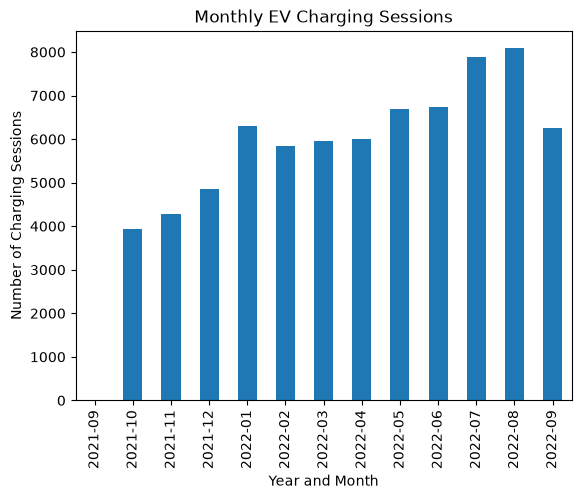

In [17]:
df["YearMonth"].value_counts().sort_index().plot(kind="bar")

plt.xlabel("Year and Month")
plt.ylabel("Number of Charging Sessions")
plt.title("Monthly EV Charging Sessions")
plt.show()

# Step 36 — Total Charging Demand by Year and Month

In [18]:
df.groupby("YearMonth")["Demand"].sum().round(2)

YearMonth
2021-09       579.19
2021-10     64933.48
2021-11     71741.55
2021-12     85158.09
2022-01    109688.78
2022-02    103219.79
2022-03    104003.60
2022-04    104414.29
2022-05    115352.49
2022-06    117564.42
2022-07    139686.65
2022-08    143041.27
2022-09    111192.61
Freq: M, Name: Demand, dtype: float64

# Step 37 — Monthly Charging Demand Chart

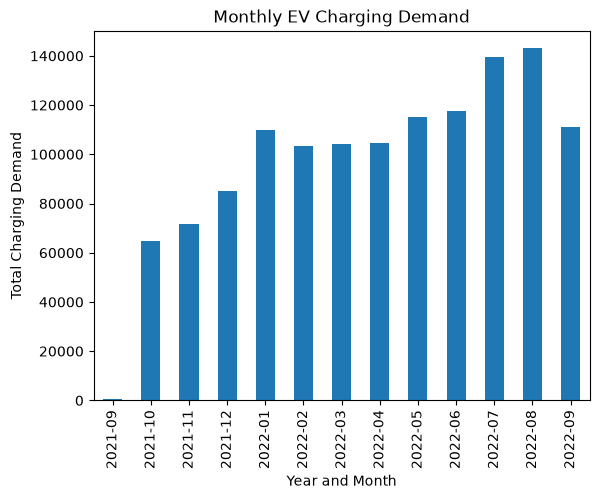

In [19]:
df.groupby("YearMonth")["Demand"].sum().plot(kind="bar")

plt.xlabel("Year and Month")
plt.ylabel("Total Charging Demand")
plt.title("Monthly EV Charging Demand")
plt.show()

# Step 38 — Check Dataset Date Range

In [20]:
print("First Date:", df["StartDatetime"].min())
print("Last Date:", df["StartDatetime"].max())

First Date: 2021-09-30 17:14:00
Last Date: 2022-09-30 23:11:00


# Step 39 — Recorded Days per Month

In [21]:
df.groupby("YearMonth")["StartDatetime"].apply(
    lambda x: x.dt.date.nunique()
)

YearMonth
2021-09     1
2021-10    31
2021-11    30
2021-12    31
2022-01    31
2022-02    28
2022-03    31
2022-04    30
2022-05    31
2022-06    30
2022-07    31
2022-08    31
2022-09    30
Freq: M, Name: StartDatetime, dtype: int64

# Step 40 — Average Daily Charging Demand by Month

In [22]:
monthly_demand = df.groupby("YearMonth")["Demand"].sum()

days_per_month = df.groupby("YearMonth")["StartDatetime"].apply(
    lambda x: x.dt.date.nunique()
)

average_daily_demand = monthly_demand / days_per_month

average_daily_demand.loc["2021-10":].round(2)

YearMonth
2021-10    2094.63
2021-11    2391.39
2021-12    2747.04
2022-01    3538.35
2022-02    3686.42
2022-03    3354.95
2022-04    3480.48
2022-05    3721.05
2022-06    3918.81
2022-07    4506.02
2022-08    4614.23
2022-09    3706.42
Freq: M, dtype: float64

# Step 41 — Average Daily Charging Demand Chart

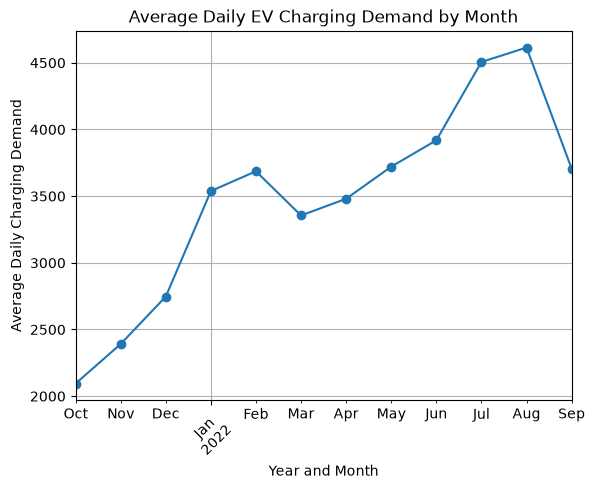

In [23]:
average_daily_demand.loc["2021-10":].plot(kind="line", marker="o")

plt.xlabel("Year and Month")
plt.ylabel("Average Daily Charging Demand")
plt.title("Average Daily EV Charging Demand by Month")
plt.xticks(rotation=45)
plt.grid(True)
plt.show()

# Step 42 — Total Charging Demand by Date

In [24]:
df["Date"] = df["StartDatetime"].dt.date

daily_demand = df.groupby("Date")["Demand"].sum()

daily_demand.head(10)

Date
2021-09-30     579.19
2021-10-01    2467.59
2021-10-02    2087.75
2021-10-03    1928.25
2021-10-04    1768.66
2021-10-05    2530.86
2021-10-06    2300.17
2021-10-07    2113.15
2021-10-08    2266.41
2021-10-09    1688.26
Name: Demand, dtype: float64